# Sample-to-Sample Correlations

Quantifies how similar individual single-cell proteomes are to each other — within the same lab (intra-lab) and across labs (inter-lab) — and tests whether cross-lab similarity depends on the instrument platform used. The analysis answers three questions:

1. **Within each lab, how reproducible are single-cell profiles?** High intra-lab correlation indicates consistent sample preparation and instrument performance.
2. **Across labs, do cells from the same cell line resemble each other?**
3. **Does instrument type drive cross-lab similarity?** Pairs from labs running the same platform may correlate more strongly than pairs spanning different platforms (e.g. Astral–Orbitrap), revealing a technology-driven component of the similarity structure.

**Key methodological choice** — raw intensities cannot be compared directly across labs because missingness patterns differ: a protein absent in one lab but present in another would artificially deflate their correlation. A three-step reference set is therefore constructed before any correlation is computed (see §2.1), ensuring that each lab's protein matrix has been filtered to a common detectable proteome with equalised missingness.

**Inputs** (`Data/AnnData/`)

| File | Description |
|---|---|
| `adata_protein.h5ad` | Protein-level quantification; `X_log2` layer used for correlation |

**Outputs** (`Figures/Figure_5/`)

| Subfolder | File pattern | Description |
|---|---|---|
| `Diagnostic_plots/` | `pct_masking` | % values masked per lab to equalise missingness |
| `Diagnostic_plots/` | `masking_heatmap_{condition}` | Binary identification heatmap after masking |
| `Diagnostic_plots/` | `missingness_distribution_protein/sample` | KDE + KS test of missingness distributions |
| `Diagnostic_plots/` | `Coobserved_diagnostic_plot` | Co-observed protein count vs correlation scatter |
| `Intralab/` | `{cond}_{method}_intralab` | Per-lab intra-lab correlation violin plots |
| `Interlab/` | `{cond}_{method}_interlab_heatmap` | Clustered median correlation heatmap |
| `Instrument/` | `{cond}_{method}_instrument` | Correlation grouped by instrument type combination |
| `Pairwise_examples/` | `{lab_a}__{lab_b}__pearson{range}` | Scatter plots of randomly sampled cell pairs |

## Imports

In [20]:
import os
from tqdm import tqdm
from pathlib import Path
import anndata
import pandas as pd
from itertools import combinations

from SCI_py.metrics.correlations import (
    create_reference_set, 
    compute_pairwise_correlations,
    compute_pairwise_stats
)
from SCI_py.plot.correlations import (
    # Diagnostics
    plot_masking_stats,
    plot_masking_heatmap,
    plot_missingness_distributions,
    plot_coobserved_diagnostic,
    # Correlations
    plot_intralab_correlation,
    plot_interlab_correlation_heatmap,
    plot_instrument_correlation,
    plot_sample_pair_correlations,
    plot_intralab_pairwise_stats
)

tqdm.pandas()

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables for CI or cross-machine runs.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

AnnData objects are read from `ROOT_OUT/AnnData/out`, produced by `02_QC_Metrics.ipynb` (which attaches the `completeness_outlier` flag).

In [21]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/DIANN/second_pass"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

ANNDATA_IN = os.path.join(
    ROOT_OUT,
    'AnnData',
    'DIANN',
    'second_pass',
    'out'
)

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures/DIANN/second_pass


## 1. Load Data

Load the protein-level AnnData object. The `X_log2` layer (log₂-transformed intensities) is used for all correlations — log-transformation compresses the dynamic range and makes the assumption of linearity more appropriate for Pearson correlation. The four conditions cover both primary cell-line measurements (K562, HEK293T) and QC injections (site-specific QC, QC - HeLa). Samples flagged as `completeness_outlier` are excluded before reference set construction.

In [22]:
adata_precursor = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_precursor.h5ad')
)
adata_protein = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_protein.h5ad')
)

conditions = ['K562', 'HEK293T', 'Site specific QC', 'QC - Hela']

In [23]:
adata_protein

AnnData object with n_obs × n_vars = 2587 × 6321
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type', 'n_proteins_withCont', 'n_proteins', 'pct_contaminant', 'completeness_sample_SC', 'completeness_sample_QC', 'completeness_outlier'
    var: 'Protein.Ids', 'Protein.Names', 'Genes', 'Contaminant', 'completeness_feature_Astral_1_SC', 'completeness_feature_Astral_2_SC', 'completeness_feature_Astral_3_SC', 'completeness_feature_Astral_4_SC', 'completeness_feature_Astral_5_SC'

## 2. Prepare Reference Set and Compute Correlations

Pairwise sample correlations over the full protein matrix would be dominated by missingness artefacts: labs with different detection rates share different subsets of proteins, so a naive Pearson or Spearman across all proteins would reflect missingness structure more than biological signal. Three preparatory steps transform the raw data into a fair comparison:

1. **Reference protein selection** — restrict to proteins detected in ≥ 75% of samples in *every* lab (the common detectable proteome).
2. **Sample quality filter** — remove samples whose protein count falls too far below the per-lab median (configurable; set to 0 here because `completeness_outlier` has already handled this).
3. **Missingness equalisation** — randomly mask observed values so each lab's per-protein missingness matches the worst-case lab. This ensures that no lab gains a correlation advantage simply from having denser data.

After masking, all pairwise correlations are computed over co-observed proteins only, avoiding any imputation.

Noteworthy: The missingness structure between labs is not exactly the same, yet harsher filtering would reduce the data used for correlation calculation. Thresholds can be changed by the user to explore the effect of this. Here, given thresholds were chosen which balance correlation comparison across different missingness structures while retaining as much information as possible.

### 2.1. Creating the Reference Set

`create_reference_set` applies the three steps above and returns:

- `masked_dict` — `{condition: {lab: X_masked}}` — per-condition, per-lab matrices in log₂ space with equalised missingness.
- `stats_df` — per-lab masking statistics (how many values were masked, percentage of total observed).

**Parameters used:**

| Parameter | Value | Meaning |
|---|---|---|
| `layer` | `'X_log2'` | Use log₂-transformed intensities |
| `min_protein_completeness` | `0.75` | Keep only proteins detected in ≥ 75% of samples in *all* labs |
| `min_sample_completeness` | `0` | No additional sample filter (outliers already removed) |

The console output reports how many reference proteins survive the cross-lab completeness filter per condition.

In [27]:
masked_dict, stats_df = create_reference_set(
    adata_protein[
        ~adata_protein.obs['completeness_outlier']
    ],
    layer='X_log2',
    conditions=conditions,
    min_sample_completeness=0,
    min_protein_completeness=.75
)

K562: 468 reference proteins
HEK293T: 474 reference proteins
Site specific QC: 1019 reference proteins
QC - Hela: 1046 reference proteins


### 2.2. Diagnostics on Reference Set Construction

Before computing correlations, three diagnostic figures verify that the masking procedure worked as intended. These are quality-control checks; unexpected patterns here would indicate a problem with the reference set construction and warrant revisiting the `min_protein_completeness` threshold.

**`plot_masking_stats`** — horizontal bar chart of % values masked per lab, one panel per condition. A dashed line marks the mean. If one lab required far more masking than others (> 20–30%), it may indicate that lab had substantially higher data density, and the reference proteome may be dominated by its missingness structure.

**`plot_masking_heatmap`** — binary identification matrix (protein × sample) per lab after masking, with rows and columns sorted by identification count. The identification patterns should look visually similar across labs after masking — uniform density confirms successful equalisation. A lab with a clearly different sparsity pattern warrants investigation.

**`plot_missingness_distributions`** — KDE of per-protein missingness fraction across labs, plus a pairwise Kolmogorov-Smirnov test matrix (BH-corrected). If missingness was equalised successfully, the KDE curves should overlap and the KS statistics should be low. Significant KS results mean the masking did not fully equalize one lab pair and pairwise correlations involving those labs should be interpreted with caution.

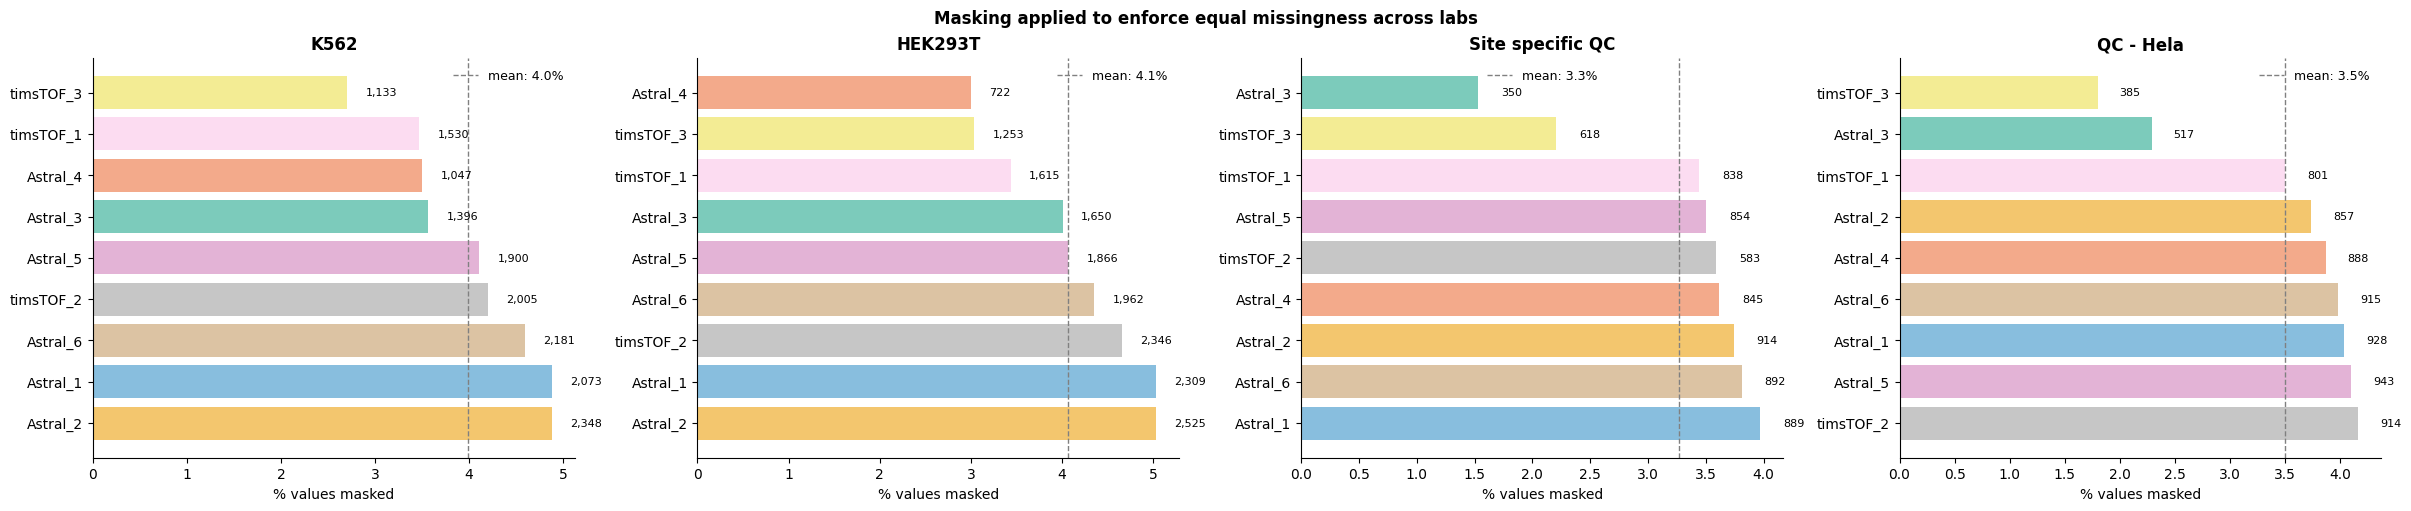

In [29]:
plot_masking_stats(
    stats_df=stats_df,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Diagnostic_plots'),
    filename='pct_masking',
    show=True
)

In [30]:
for condition in conditions:
    plot_masking_heatmap(
        masked_data=masked_dict,
        condition=condition,
        save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Diagnostic_plots'),
        filename=f'masking_heatmap_{condition}',
        show=False
    )

In [31]:
for cond_label, cond in {
    'SC': ['K562', 'HEK293T'],
    'K562': ['K562'],
    'HEK293T': ['HEK293T']
}.items():
    ks_results = plot_missingness_distributions(
        masked_dict,
        conditions=cond,
        level='protein',
        save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Diagnostic_plots'),
        filename=f'missingness_distribution_protein_{cond_label}',
        xlim_max=.3,
        show=False
    )
    ks_results = plot_missingness_distributions(
        masked_dict,
        conditions=cond,
        level='sample',
        save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Diagnostic_plots'),
        filename=f'missingness_distribution_sample_{cond_label}',
        xlim_max=.3,
        show=False
    )

### 2.3. Compute Pairwise Correlations

`compute_pairwise_correlations` iterates over all *n(n−1)/2* sample pairs within each condition and computes both Pearson (on log₂ values) and Spearman (on column-wise ranks) correlations over co-observed proteins only. Pairs where fewer than `min_coobserved = 50` proteins are jointly observed are set to `NaN` and excluded.

Each pair is classified into one of three comparison types:

| Type | Definition |
|---|---|
| `intra_lab` | Both samples from the same lab |
| `inter_lab_same_instrument` | Different labs, same instrument platform (e.g. both Astral) |
| `inter_lab_diff_instrument` | Different labs, different instrument platforms |

The result is a dict mapping condition → DataFrame with one row per valid sample pair, carrying both correlation values, comparison type, lab metadata, and co-observation counts. This DataFrame is the input to all downstream visualisations.

In [32]:
correlation_results = compute_pairwise_correlations(
    masked_data=masked_dict,
    conditions=conditions,
    adata=adata_protein[
        ~adata_protein.obs['completeness_outlier']
    ],
    min_coobserved=100,
)

K562: 837 samples × 468 proteins → 349,866 pairs


K562: 100%|██████████| 837/837 [01:52<00:00,  7.44it/s] 


  Done: 349,866 valid pairs
HEK293T: 834 samples × 474 proteins → 347,361 pairs


HEK293T: 100%|██████████| 834/834 [01:51<00:00,  7.48it/s]


  Done: 347,361 valid pairs
Site specific QC: 207 samples × 1019 proteins → 21,321 pairs


Site specific QC: 100%|██████████| 207/207 [00:08<00:00, 24.99it/s]


  Done: 21,321 valid pairs
QC - Hela: 196 samples × 1046 proteins → 19,110 pairs


QC - Hela: 100%|██████████| 196/196 [00:07<00:00, 26.32it/s]


  Done: 19,110 valid pairs


In [10]:
# TODO (Minor): Need to change the saving here to obsp instead of uns
adata_protein.uns['correlations'] = correlation_results

#### Co-observation Diagnostic

`plot_coobserved_diagnostic` validates that the `min_coobserved = 50` threshold is appropriate and that intra- and inter-lab pairs have comparable co-observation depth. Two panels per condition:

1. **Co-observed protein count KDE per comparison type** — if intra-lab pairs have systematically more co-observed proteins than inter-lab pairs, any correlation gap between the two groups could be a depth artefact rather than a biology signal. The curves should substantially overlap.
2. **Co-observed count vs correlation scatter** — if correlation increases monotonically with co-observed count, the threshold is too low and pairs near 50 proteins are under-powered. A flat binned-mean curve above the threshold confirms that 50 is sufficient.

In [11]:
plot_coobserved_diagnostic(
    correlation_results=correlation_results,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Diagnostic_plots'),
    filename='Coobserved_diagnostic_plot',
    show=False
)

## 3. Intra-lab Correlations

Within each lab, all unique cell pairs are correlated. High intra-lab correlation means that cells of the same type, prepared and measured in the same lab, have highly similar protein abundance profiles — the expected result for a homogeneous cell line. Low intra-lab correlation would indicate poor measurement reproducibility (preparation noise, injection-to-injection instability) or genuine biological heterogeneity in the cell population.

`plot_intralab_correlation` draws a violin plot per lab, with labs ordered by median correlation (highest on the left). The inner quartile lines show Q1, median, and Q3. Both Spearman and Pearson are plotted separately: Spearman is robust to intensity scale differences and outliers; Pearson is more sensitive to absolute quantitative agreement.

In [12]:
plot_intralab_correlation(
    correlation_results=correlation_results,
    method='spearman',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Intralab'),
    filename_fmt='{cond}_{method}_intralab.png',
    show=False
)

plot_intralab_correlation(
    correlation_results=correlation_results,
    method='pearson',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Intralab'),
    filename_fmt='{cond}_{method}_intralab.png',
    show=False
)

## 4. Inter-lab Correlations

Cross-lab correlation answers: does a cell measured in lab A look like a cell measured in lab B? Because we are comparing different individual cells (not the same cell run twice), we expect inter-lab correlations to be lower than intra-lab correlations — but not dramatically so if the protocol is robust.

`plot_interlab_correlation_heatmap` builds a symmetric matrix where:
- **Diagonal** = median intra-lab correlation for that lab.
- **Off-diagonal** = median correlation between all pairs of samples from the two labs.

The matrix is hierarchically clustered so that labs with similar inter-lab correlation profiles are grouped together. A gradient from red (low) to green (high) maps absolute correlation values.

In [13]:
plot_interlab_correlation_heatmap(
    correlation_results=correlation_results,
    method='spearman',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Interlab'),
    filename_fmt='{cond}_{method}_interlab_heatmap.png',
    show=False
)

plot_interlab_correlation_heatmap(
    correlation_results=correlation_results,
    method='pearson',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Interlab'),
    filename_fmt='{cond}_{method}_interlab_heatmap.png',
    show=False
)

## 5. Instrument-type Comparison

Decomposes inter-lab correlation by instrument platform. If the correlation between two cells from different labs is primarily driven by the biology, it should not matter whether both labs use the same mass spectrometer platform. If it does matter — i.e. same-instrument inter-lab pairs correlate higher than mixed-instrument pairs — that indicates a technology-dependent component in what is quantified.

`plot_instrument_correlation` groups sample pairs into:
- `intra_lab` — within-lab pairs (benchmark).
- `inter_{platform}` — cross-lab pairs where both labs run the same platform.
- `inter_{platform_A}__{platform_B}` — cross-lab pairs spanning two different platforms.

Results are shown as violin plots, enabling direct comparison of the within- and across-instrument distributions.

In [14]:
plot_instrument_correlation(
    correlation_results=correlation_results,
    method='spearman',
    ylim=(-1,1),
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Instrument'),
    filename_fmt='{cond}_{method}_instrument.png',
    show=False
)

plot_instrument_correlation(
    correlation_results=correlation_results,
    method='pearson',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Instrument'),
    filename_fmt='{cond}_{method}_instrument.png',
    show=False    
)

## 6. Sample-pair Scatter Plots

Provides an interpretable view of what a particular correlation value looks like in practice. `plot_sample_pair_correlations` randomly samples `n_pairs` cell pairs from a specified lab pair and correlation range, then plots the log₂ intensities of one cell against the other for each pair.

Each subplot shows:
- One point per co-observed protein (blue scatter, α = 0.3).
- A linear regression line (red) fit to the co-observed subset.
- The Pearson correlation and co-observation count in the title.

This is particularly useful for quality checking: a high-correlation pair should show a tight linear cloud; a low-correlation pair may show a diffuse scatter

In [16]:
plot_sample_pair_correlations(
    correlation_results=correlation_results,
    masked_data=masked_dict,
    condition='K562',
    lab_pair=('Astral_1', 'Astral_2'),
    method='pearson',
    n_pairs=6,
    corr_range=(.85, .9),
    random_seed=42,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Pairwise_examples'),
    filename='Astral_1__Astral_2__pearson85_90',
    show=False
)

plot_sample_pair_correlations(
    correlation_results=correlation_results,
    masked_data=masked_dict,
    condition='K562',
    lab_pair=('Astral_1', 'Astral_2'),
    method='pearson',
    n_pairs=6,
    corr_range=(.7, .75),
    random_seed=42,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Pairwise_examples'),
    filename='Astral_1__Astral_2__pearson70_75',
    show=False
)

## 7. Statistical Testing of Intra-lab Reproducibility

Tests whether observed differences in intra-lab correlation between labs are statistically and practically significant, using a non-parametric two-group comparison.

**Test** — Mann-Whitney U (Wilcoxon rank-sum) comparing the intra-lab correlation distributions of each lab pair. The p-value is reported but should be interpreted with caution: with thousands of pairs per lab, the test is extremely powerful and nearly any delta will be "significant". The primary effect size is therefore the **median delta** (Δ = median(lab A) − median(lab B)).

**Effect size** — the Common Language Effect Size (CLES) reports the probability that a randomly drawn correlation from lab A exceeds one from lab B. CLES = 0.5 means no difference; thresholds: > 0.56 small, > 0.64 medium, > 0.71 large effect.

**Practical significance** — a pair is flagged as `practical_sig = True` only if `|Δ| ≥ 0.02` (2 correlation units), a pre-specified threshold representing a meaningful reproducibility difference.

`plot_intralab_pairwise_stats` visualises this as three panels per condition:
1. **Δ heatmap** — signed median correlation difference for every lab pair.
2. **CLES heatmap** — effect size of the same comparisons.
3. **Δ distribution** — histogram of all pairwise deltas, showing whether reproducibility differences are systematic or isolated.

In [17]:
# Stats — you decide how to group
stats_list = []
for cond, df in correlation_results.items():
    intra = df[df['same_lab']].dropna(subset=['spearman'])
    labs  = intra['lab_i'].unique()

    df = pd.DataFrame([
        compute_pairwise_stats(
            intra[intra['lab_i'] == la]['pearson'],
            intra[intra['lab_i'] == lb]['pearson'],
            la, lb,
        )
        for la, lb in combinations(labs, 2)
    ])
    df['condition'] = cond
    stats_list.append(df)
df = pd.concat(stats_list)

In [18]:
plot_intralab_pairwise_stats(
    stats_df=df,
    method='pearson',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_5', 'Reproducibility'),
    filename='intralab_reproducibility_comparison',
    show=False
)

## 8. Save

In [19]:
ANNDATA_OUT = os.path.join(
    ROOT_OUT,
    'AnnData',
    'DIANN',
    'second_pass',
    'out'
)

adata_precursor.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
    convert_strings_to_categoricals=False
)